In [1]:
# ============================================================
# CONSOLIDATED SETUP CELL — run this FIRST after every restart
# Defines: device, transforms, mask functions, dataset classes,
# model architecture, training function.
# Does NOT include: downloading pet_dataset or COCO image_paths
# (those stay as separate cells since they involve actual downloads).
# ============================================================

import os
import time
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import spectral_norm
from torch.utils.data import Dataset, DataLoader, random_split, Subset
from torchvision import datasets, transforms
import torchvision.models as models

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# ------------------------------------------------------------
# Image transform (shared by pet + crowd pipelines)
# ------------------------------------------------------------
IMAGE_SIZE = 256

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])
crowd_transform = image_transform  # identical normalization, kept as alias for clarity

# ------------------------------------------------------------
# Mask generators
# ------------------------------------------------------------
def create_irregular_mask(height=256, width=256, min_ellipses=5, max_ellipses=12):
    """Scattered small-ellipse mask (original pet-training mask style)."""
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    num_ellipses = random.randint(min_ellipses, max_ellipses)
    for _ in range(num_ellipses):
        cx = random.randint(0, width)
        cy = random.randint(0, height)
        rx = random.randint(8, 35)
        ry = random.randint(8, 35)
        draw.ellipse((cx - rx, cy - ry, cx + rx, cy + ry), fill=255)
    mask = transforms.ToTensor()(mask)
    return (mask > 0).float()


def create_large_blob_mask(height=256, width=256):
    """Single large region -- simulates removing one whole object/person."""
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    cx = random.randint(width // 4, 3 * width // 4)
    cy = random.randint(height // 4, 3 * height // 4)
    rw = random.randint(width // 6, width // 3)
    rh = random.randint(height // 4, height // 2)
    draw.ellipse((cx - rw, cy - rh, cx + rw, cy + rh), fill=255)
    mask = transforms.ToTensor()(mask)
    return (mask > 0).float()


def create_mixed_mask(height=256, width=256, large_blob_prob=0.3):
    """70% scattered ellipses, 30% one large blob."""
    if random.random() < large_blob_prob:
        return create_large_blob_mask(height, width)
    else:
        return create_irregular_mask(height, width)

# ------------------------------------------------------------
# Dataset classes
# ------------------------------------------------------------
class InpaintingDataset(Dataset):
    """Pet dataset -- uses create_irregular_mask (small scattered ellipses)."""
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, _ = self.base_dataset[idx]
        original_image = image_transform(image)
        mask = create_irregular_mask(IMAGE_SIZE, IMAGE_SIZE)
        masked_image = original_image * (1 - mask)
        return masked_image, mask, original_image


class CrowdInpaintingDataset(Dataset):
    """Crowd/COCO dataset -- uses create_mixed_mask (ellipses + large blobs)."""
    def __init__(self, image_paths, transform):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")
        original_image = self.transform(image)
        mask = create_mixed_mask(IMAGE_SIZE, IMAGE_SIZE)
        masked_image = original_image * (1 - mask)
        return masked_image, mask, original_image

# ------------------------------------------------------------
# Model: Gated convolutions
# ------------------------------------------------------------
class GatedConv2d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0,
                 dilation=1, activation=nn.LeakyReLU(0.2, inplace=True)):
        super().__init__()
        self.feature_conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding, dilation)
        self.gate_conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding, dilation)
        self.norm = nn.InstanceNorm2d(out_ch, affine=True)
        self.activation = activation

    def forward(self, x):
        feat = self.feature_conv(x)
        gate = torch.sigmoid(self.gate_conv(x))
        out = self.norm(feat * gate)
        if self.activation is not None:
            out = self.activation(out)
        return out


class GatedDeconv2d(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.gated_conv = GatedConv2d(in_ch, out_ch, 3, 1, 1)

    def forward(self, x):
        return self.gated_conv(self.up(x))


class ResidualDilatedGatedBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()
        self.conv1 = GatedConv2d(channels, channels, 3, 1, dilation, dilation)
        self.conv2 = GatedConv2d(channels, channels, 3, 1, dilation, dilation, activation=None)
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x):
        out = self.conv2(self.conv1(x))
        return self.act(x + out)

# ------------------------------------------------------------
# Model: Generator
# ------------------------------------------------------------
class InpaintingGeneratorV2(nn.Module):
    def __init__(self, in_channels: int = 4, base_channels: int = 64):
        super().__init__()
        c = base_channels

        self.enc0 = GatedConv2d(in_channels, c, 7, 1, 3)
        self.enc1 = GatedConv2d(c, c * 2, 4, 2, 1)
        self.enc2 = GatedConv2d(c * 2, c * 4, 4, 2, 1)

        self.bottleneck = nn.Sequential(
            ResidualDilatedGatedBlock(c * 4, dilation=2),
            ResidualDilatedGatedBlock(c * 4, dilation=4),
            ResidualDilatedGatedBlock(c * 4, dilation=8),
            ResidualDilatedGatedBlock(c * 4, dilation=16),
        )

        self.up1 = GatedDeconv2d(c * 4, c * 2)
        self.dec1 = GatedConv2d(c * 2 + c * 2, c * 2, 3, 1, 1)

        self.up2 = GatedDeconv2d(c * 2, c)
        self.dec2 = GatedConv2d(c + c, c, 3, 1, 1)

        self.out_conv = nn.Sequential(
            nn.Conv2d(c, 3, 7, 1, 3),
            nn.Tanh(),
        )

    def forward(self, image, mask):
        x = torch.cat([image, mask], dim=1)
        e0 = self.enc0(x)
        e1 = self.enc1(e0)
        e2 = self.enc2(e1)
        b = self.bottleneck(e2)
        d1 = self.up1(b)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e0], dim=1))
        out = self.out_conv(d2)
        return image * (1 - mask) + out * mask

# ------------------------------------------------------------
# Model: Discriminator
# ------------------------------------------------------------
class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels: int = 3, base_channels: int = 64):
        super().__init__()
        c = base_channels

        def block(in_c, out_c, stride=2, norm=True):
            layers = [spectral_norm(nn.Conv2d(in_c, out_c, 4, stride, 1))]
            if norm:
                layers.append(nn.InstanceNorm2d(out_c, affine=True))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(in_channels, c, norm=False),
            *block(c, c * 2),
            *block(c * 2, c * 4),
            *block(c * 4, c * 8, stride=1),
            spectral_norm(nn.Conv2d(c * 8, 1, 4, 1, 1)),
        )

    def forward(self, x):
        return self.model(x)

# ------------------------------------------------------------
# Perceptual + style loss
# ------------------------------------------------------------
class VGGPerceptualLoss(nn.Module):
    def __init__(self, layer_ids=(3, 8, 15, 22)):
        super().__init__()
        vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
        self.vgg = vgg.eval()
        for p in self.vgg.parameters():
            p.requires_grad = False
        self.layer_ids = set(layer_ids)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def _preprocess(self, x):
        x = (x + 1) / 2
        return (x - self.mean) / self.std

    def _extract(self, x):
        feats = []
        x = self._preprocess(x)
        for idx, layer in enumerate(self.vgg):
            x = layer(x)
            if idx in self.layer_ids:
                feats.append(x)
        return feats

    def forward(self, fake, real):
        fake_feats = self._extract(fake)
        real_feats = self._extract(real)
        perceptual_loss = 0.0
        style_loss = 0.0
        for f, r in zip(fake_feats, real_feats):
            perceptual_loss = perceptual_loss + F.l1_loss(f, r)
            b, ch, h, w = f.shape
            f_flat = f.view(b, ch, h * w)
            r_flat = r.view(b, ch, h * w)
            gram_f = torch.bmm(f_flat, f_flat.transpose(1, 2)) / (ch * h * w)
            gram_r = torch.bmm(r_flat, r_flat.transpose(1, 2)) / (ch * h * w)
            style_loss = style_loss + F.l1_loss(gram_f, gram_r)
        return perceptual_loss, style_loss

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def set_requires_grad(module: nn.Module, flag: bool):
    for p in module.parameters():
        p.requires_grad = flag


def adversarial_weight_schedule(epoch: int, warmup_epochs: int = 10, final_weight: float = 0.1) -> float:
    if epoch >= warmup_epochs:
        return final_weight
    return final_weight * (epoch / warmup_epochs)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
def train(
    generator, discriminator, train_loader, val_loader, device,
    start_epoch=1, end_epoch=100,
    lambda_rec=10.0, lambda_perceptual=1.0, lambda_style=30.0,
    lr_g=2e-4, lr_d=2e-4,
    checkpoint_dir="checkpoints",
):
    os.makedirs(checkpoint_dir, exist_ok=True)

    criterion_gan = nn.BCEWithLogitsLoss()
    perceptual_loss_fn = VGGPerceptualLoss().to(device)

    optimizer_G = torch.optim.Adam(generator.parameters(), lr=lr_g, betas=(0.5, 0.999))
    optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=lr_d, betas=(0.5, 0.999))

    scheduler_G = torch.optim.lr_scheduler.StepLR(optimizer_G, step_size=max(end_epoch // 2, 1), gamma=0.5)
    scheduler_D = torch.optim.lr_scheduler.StepLR(optimizer_D, step_size=max(end_epoch // 2, 1), gamma=0.5)

    for epoch in range(start_epoch, end_epoch + 1):
        generator.train()
        discriminator.train()
        lambda_adv = adversarial_weight_schedule(epoch)

        epoch_stats = {"G_total": 0.0, "G_rec": 0.0, "G_perc": 0.0, "G_style": 0.0, "G_adv": 0.0, "D": 0.0}
        start_time = time.time()

        for batch_idx, (masked_images, masks, original_images) in enumerate(train_loader):
            masked_images = masked_images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            original_images = original_images.to(device, non_blocking=True)

            fake_images = generator(masked_images, masks)

            set_requires_grad(discriminator, True)
            real_pred = discriminator(original_images)
            fake_pred = discriminator(fake_images.detach())
            real_labels = torch.full_like(real_pred, 0.9)
            fake_labels = torch.zeros_like(fake_pred)
            loss_D = (criterion_gan(real_pred, real_labels) + criterion_gan(fake_pred, fake_labels)) / 2
            optimizer_D.zero_grad(); loss_D.backward(); optimizer_D.step()

            set_requires_grad(discriminator, False)
            fake_pred = discriminator(fake_images)
            loss_G_adv = criterion_gan(fake_pred, torch.ones_like(fake_pred))

            masked_l1 = torch.abs(fake_images - original_images) * masks
            loss_G_rec = masked_l1.sum() / (masks.sum() * 3 + 1e-8)
            loss_G_perceptual, loss_G_style = perceptual_loss_fn(fake_images, original_images)

            loss_G = (lambda_rec * loss_G_rec + lambda_perceptual * loss_G_perceptual
                      + lambda_style * loss_G_style + lambda_adv * loss_G_adv)
            optimizer_G.zero_grad(); loss_G.backward(); optimizer_G.step()

            epoch_stats["G_total"] += loss_G.item()
            epoch_stats["G_rec"] += loss_G_rec.item()
            epoch_stats["G_perc"] += loss_G_perceptual.item()
            epoch_stats["G_style"] += loss_G_style.item()
            epoch_stats["G_adv"] += loss_G_adv.item()
            epoch_stats["D"] += loss_D.item()

            if (batch_idx + 1) % 25 == 0:
                print(f"[Epoch {epoch}/{end_epoch}] Batch [{batch_idx+1}/{len(train_loader)}] "
                      f"D: {loss_D.item():.4f} G: {loss_G.item():.4f} lambda_adv={lambda_adv:.3f}")

        scheduler_G.step(); scheduler_D.step()
        n = len(train_loader)
        print(f"\nEpoch [{epoch}/{end_epoch}] completed in {time.time()-start_time:.1f}s")
        for k, v in epoch_stats.items():
            print(f"  {k}: {v/n:.4f}")
        print("-" * 60)

        torch.save({
            "epoch": epoch,
            "generator": generator.state_dict(),
            "discriminator": discriminator.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
        }, os.path.join(checkpoint_dir, f"gan_v2_epoch{epoch}.pth"))
        print(f"Checkpoint saved: gan_v2_epoch{epoch}.pth")

print("\n✅ Consolidated setup complete — all classes/functions defined.")
print("Still need (separately, only once per session):")
print("  - pet_dataset  = datasets.OxfordIIITPet(root='./data', split='trainval', target_types='category', download=True)")
print("  - image_paths  = COCO download cell (or rebuilt from disk: os.listdir('coco_person_images'))")

Using device: cpu

✅ Consolidated setup complete — all classes/functions defined.
Still need (separately, only once per session):
  - pet_dataset  = datasets.OxfordIIITPet(root='./data', split='trainval', target_types='category', download=True)
  - image_paths  = COCO download cell (or rebuilt from disk: os.listdir('coco_person_images'))


In [2]:
# SAM toolkit (missing from the pasted cell)
!pip install git+https://github.com/facebookresearch/segment-anything.git -q

import cv2
import numpy as np
from segment_anything import sam_model_registry, SamPredictor

if not os.path.exists("sam_vit_b_01ec64.pth"):
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to(device=device)
predictor = SamPredictor(sam)


def preview_with_grid(image_path, grid_step=50):
    img = Image.open(image_path).convert("RGB")
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.xticks(range(0, img.width, grid_step))
    plt.yticks(range(0, img.height, grid_step))
    plt.grid(color="red", alpha=0.3)
    plt.title("Read the approx (x, y) of a point ON the object to remove")
    plt.show()
    return img.size


def remove_object(image_path, point_xy=None, box_xyxy=None, dilate_px=5):
    assert (point_xy is not None) or (box_xyxy is not None), "Provide either point_xy or box_xyxy"
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    predictor.set_image(image_rgb)

    if point_xy is not None:
        masks, scores, _ = predictor.predict(
            point_coords=np.array([point_xy]), point_labels=np.array([1]), multimask_output=True,
        )
        raw_mask = masks[np.argmax(scores)]
    else:
        masks, scores, _ = predictor.predict(box=np.array(box_xyxy), multimask_output=False)
        raw_mask = masks[0]

    if dilate_px > 0:
        kernel = np.ones((dilate_px, dilate_px), np.uint8)
        raw_mask = cv2.dilate(raw_mask.astype(np.uint8), kernel, iterations=1)

    image_resized = cv2.resize(image_rgb, (IMAGE_SIZE, IMAGE_SIZE))
    mask_resized = cv2.resize(raw_mask.astype(np.uint8), (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_NEAREST)

    image_tensor = torch.from_numpy(image_resized).permute(2, 0, 1).float() / 255.0
    image_tensor = (image_tensor - 0.5) / 0.5
    image_tensor = image_tensor.unsqueeze(0).to(device)

    mask_tensor = torch.from_numpy(mask_resized).float().unsqueeze(0).unsqueeze(0).to(device)
    masked_image = image_tensor * (1 - mask_tensor)

    generator.eval()
    with torch.no_grad():
        output = generator(masked_image, mask_tensor)
    return image_tensor, mask_tensor, masked_image, output


def show_object_removal(image_tensor, mask_tensor, masked_image, output):
    def to_numpy(t):
        t = t.detach().cpu()[0]
        t = (t.permute(1, 2, 0) + 1) / 2
        return t.clamp(0, 1).numpy()

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(to_numpy(image_tensor));  axes[0].set_title("Original");       axes[0].axis("off")
    axes[1].imshow(mask_tensor[0, 0].cpu().numpy(), cmap="gray"); axes[1].set_title("SAM Mask"); axes[1].axis("off")
    axes[2].imshow(to_numpy(masked_image));  axes[2].set_title("Masked Input");   axes[2].axis("off")
    axes[3].imshow(to_numpy(output));        axes[3].set_title("Object Removed"); axes[3].axis("off")
    plt.tight_layout()
    plt.show()

print("✅ SAM toolkit ready.")

  Preparing metadata (setup.py) ... done
✅ SAM toolkit ready.


testing start

In [6]:
import os

checkpoint_path = "/content/gan_v2_epoch3.pth"

if os.path.exists(checkpoint_path):
    print("File size:", os.path.getsize(checkpoint_path), "bytes")
else:
    print("Checkpoint not found:", checkpoint_path)

File size: 180622411 bytes


In [7]:
import torch

checkpoint_path = "/content/gan_v2_epoch3.pth"

try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )
    print("Checkpoint loaded successfully.")
    print("Checkpoint type:", type(checkpoint))

except Exception as e:
    print("Checkpoint loading failed:")
    print(type(e).__name__, str(e))

Checkpoint loaded successfully.
Checkpoint type: <class 'dict'>


testing end

In [8]:
# ============================================
# TEST TRAINED CROWD GAN
# ============================================

import torch
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generator = InpaintingGeneratorV2(
    in_channels=4,
    base_channels=64
).to(device)

discriminator = PatchDiscriminator(
    in_channels=3,
    base_channels=64
).to(device)

# Load the CROWD checkpoint (Drive path, epoch 5 — your fine-tuning run)
checkpoint = torch.load(
    "gan_v2_epoch3.pth",
    map_location=device
)

generator.load_state_dict(checkpoint["generator"])
discriminator.load_state_dict(checkpoint["discriminator"])

generator.eval()
discriminator.eval()

print("Loaded crowd-finetuned checkpoint successfully.")
print("Epoch:", checkpoint["epoch"])

Loaded crowd-finetuned checkpoint successfully.
Epoch: 3


Saved test_pet.jpg, size: 232320


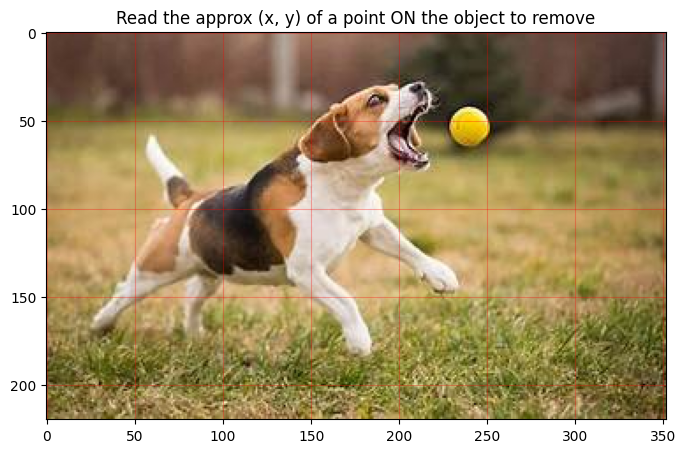

(352, 220)

In [9]:
import cv2
from google.colab.patches import cv2_imshow
img = cv2.imread('Dog_catch_ball.JPG')
print("Saved test_pet.jpg, size:", img.size)

preview_with_grid("Dog_catch_ball.JPG")

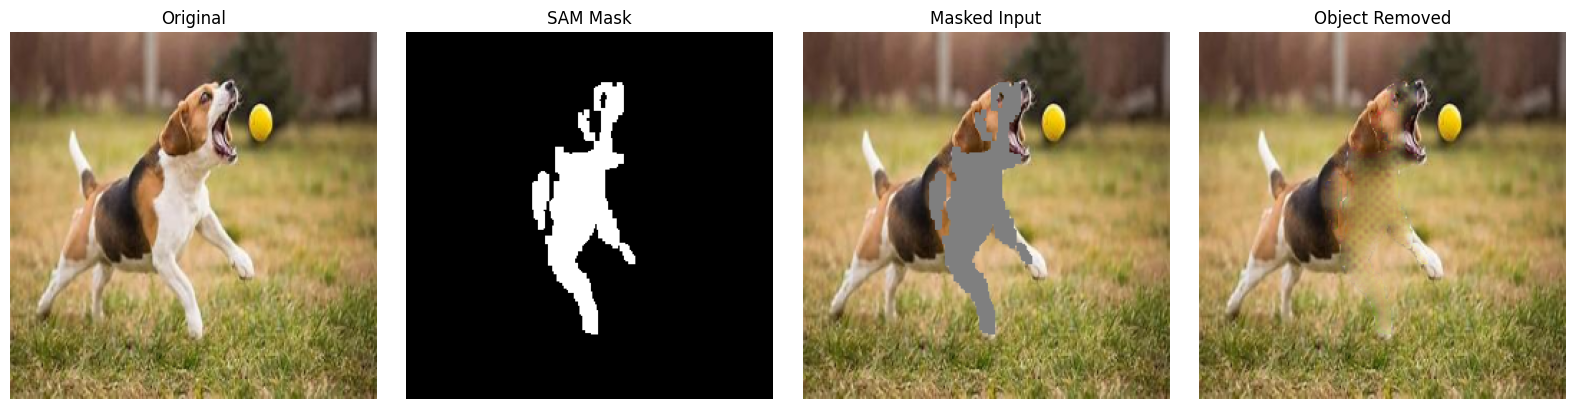

Mask coverage: 7.59%


In [10]:


image_t3, mask_t3, masked_t3, output_t3 = remove_object(
    "Dog_catch_ball.JPG",
    point_xy=(475, 100),   # <-- replace with your center-of-required object coordinate
)
show_object_removal(image_t3, mask_t3, masked_t3, output_t3)
print(f"Mask coverage: {mask_t3.mean().item() * 100:.2f}%")

Saved test_pet.jpg, size: 920322


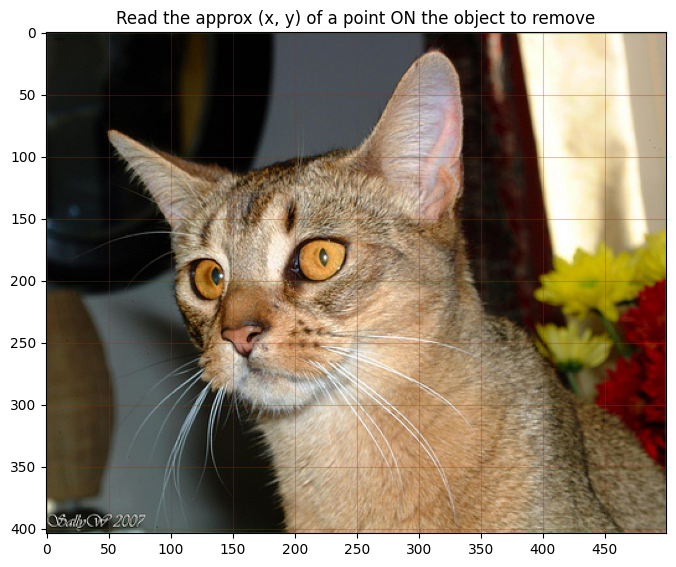

(500, 404)

In [ ]:
img2 = cv2.imread('Cat_image.jpg')
print("Saved test_pet.jpg, size:", img.size)

preview_with_grid("Cat_image.jpg")

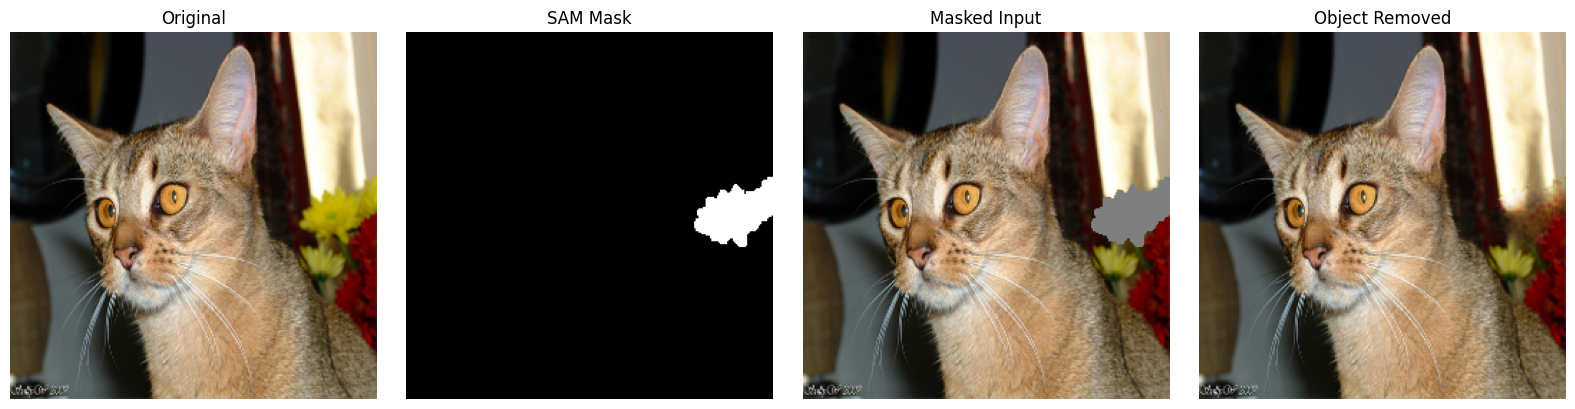

Mask coverage: 0.64%


In [ ]:

image_t2, mask_t2, masked_t2, output_t2 = remove_object(
    "Cat_image.jpg",
    point_xy=(450, 200),   # <-- replace with your center-of-required object coordinate
)
show_object_removal(image_t2, mask_t2, masked_t2, output_t2)
print(f"Mask coverage: {mask_t3.mean().item() * 100:.2f}%")